In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

analysis_table = pd.read_csv(
    "../data/processed/cluster_analysis_table.csv"
)

analysis_table.head()

,user_id,cluster,order_id,product_name,department,order_hour_of_day,order_dow,reordered
0,202279,4,2,Organic Egg Whites,dairy eggs,9,5,1
1,202279,4,2,Michigan Organic Kale,produce,9,5,1
2,202279,4,2,Garlic Powder,pantry,9,5,0
3,202279,4,2,Coconut Butter,pantry,9,5,1
4,202279,4,2,Natural Sweetener,pantry,9,5,0


In [2]:
def get_time_segment(hour):

    if 5 <= hour <= 11:
        return "Morning"

    elif 12 <= hour <= 17:
        return "Afternoon"

    elif 18 <= hour <= 21:
        return "Evening"

    else:
        return "Midnight"


analysis_table["time_segment"] = (
    analysis_table["order_hour_of_day"]
    .apply(get_time_segment)
)

analysis_table.head()

,user_id,cluster,order_id,product_name,department,order_hour_of_day,order_dow,reordered,time_segment
0,202279,4,2,Organic Egg Whites,dairy eggs,9,5,1,Morning
1,202279,4,2,Michigan Organic Kale,produce,9,5,1,Morning
2,202279,4,2,Garlic Powder,pantry,9,5,0,Morning
3,202279,4,2,Coconut Butter,pantry,9,5,1,Morning
4,202279,4,2,Natural Sweetener,pantry,9,5,0,Morning


In [3]:
time_counts = (
    analysis_table["time_segment"]
    .value_counts()
)

time_counts

time_segment
Afternoon    15267143
Morning      10950488
Evening       4670732
Midnight      1546126
Name: count, dtype: int64

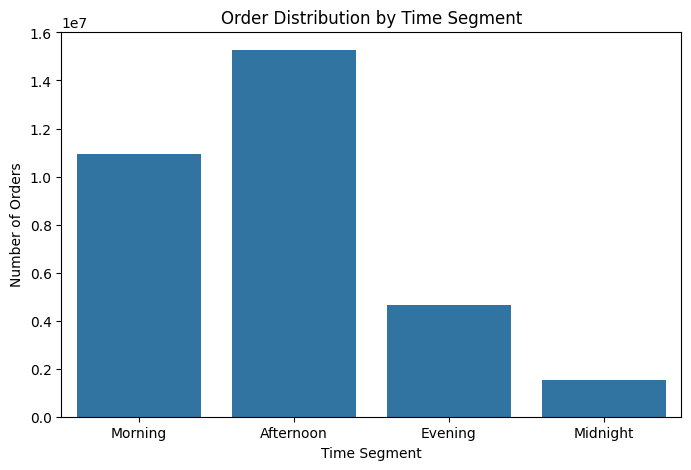

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=analysis_table,
    x="time_segment",
    order=[
        "Morning",
        "Afternoon",
        "Evening",
        "Midnight"
    ]
)

plt.title("Order Distribution by Time Segment")
plt.xlabel("Time Segment")
plt.ylabel("Number of Orders")

plt.show()

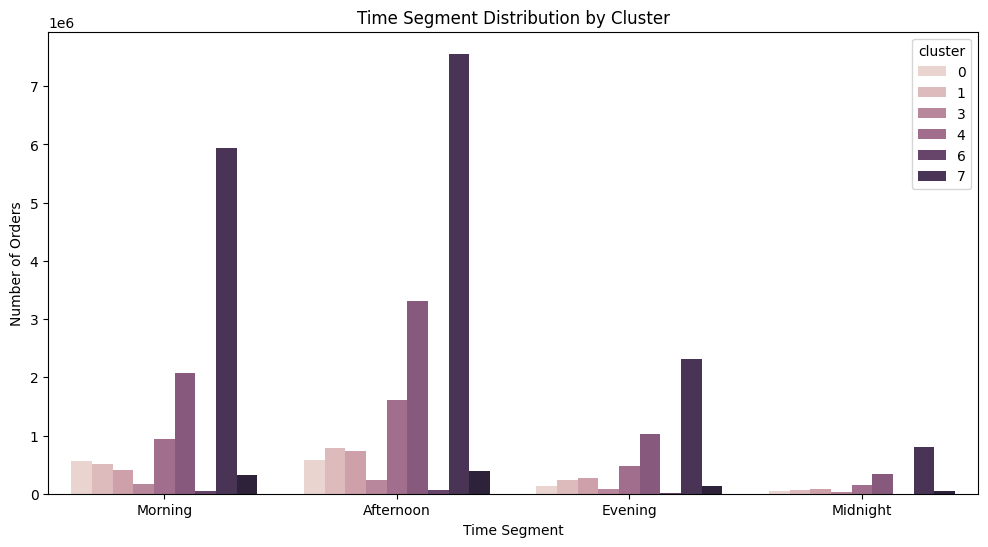

In [5]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=analysis_table,
    x="time_segment",
    hue="cluster",
    order=[
        "Morning",
        "Afternoon",
        "Evening",
        "Midnight"
    ]
)

plt.title("Time Segment Distribution by Cluster")
plt.xlabel("Time Segment")
plt.ylabel("Number of Orders")

plt.show()

In [6]:
import os

OUTPUT_DIR = "../data/processed/time_rules"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [7]:
from mlxtend.frequent_patterns import apriori, association_rules

time_segments = [
    "Morning",
    "Afternoon",
    "Evening",
    "Midnight"
]

for t in time_segments:

    print(f"\nProcessing {t}")

    time_data = analysis_table[
        analysis_table["time_segment"] == t
    ].copy()

    # 移除 produce / dairy eggs
    time_data = time_data[
        ~time_data["department"].isin(
            ["produce", "dairy eggs"]
        )
    ]

    # 只保留熱門商品
    top_products = (
        time_data["product_name"]
        .value_counts()
        .head(100)
        .index
    )

    time_data = time_data[
        time_data["product_name"].isin(top_products)
    ]

    # 建 basket
    basket = (
        time_data
        .groupby(["order_id", "product_name"])
        .size()
        .unstack(fill_value=0)
    )

    basket = (basket > 0)

    # Apriori
    frequent_items = apriori(
        basket,
        min_support=0.003,
        use_colnames=True
    )

    if frequent_items.empty:
        print(f"{t}: no frequent itemsets")
        continue

    rules = association_rules(
        frequent_items,
        metric="lift",
        min_threshold=1.0
    )

    if rules.empty:
        print(f"{t}: no rules")
        continue

    rules = rules.sort_values(
        by="lift",
        ascending=False
    )

    # 轉文字
    rules["antecedents"] = rules["antecedents"].apply(
        lambda x: ", ".join(list(x))
    )

    rules["consequents"] = rules["consequents"].apply(
        lambda x: ", ".join(list(x))
    )

    rules.to_csv(
        f"{OUTPUT_DIR}/{t}_rules.csv",
        index=False
    )

    print(f"{t} saved. Rules: {len(rules)}")


Processing Morning
Morning saved. Rules: 36

Processing Afternoon
Afternoon saved. Rules: 14

Processing Evening
Evening saved. Rules: 8

Processing Midnight
Midnight saved. Rules: 10


In [8]:
from mlxtend.frequent_patterns import apriori, association_rules
import os

OUTPUT_DIR = "../data/processed/cluster_time_rules"
os.makedirs(OUTPUT_DIR, exist_ok=True)

selected_analysis = {
    0: ["Morning", "Afternoon", "Evening", "Midnight"],
    6: ["Morning", "Afternoon", "Evening", "Midnight"],
    8: ["Morning", "Afternoon", "Evening", "Midnight"]
}

for cluster_id, time_list in selected_analysis.items():

    for time_seg in time_list:

        print(f"\nCluster {cluster_id} - {time_seg}")

        data = analysis_table[
            (analysis_table["cluster"] == cluster_id) &
            (analysis_table["time_segment"] == time_seg)
        ].copy()

        # remove produce / dairy eggs
        data = data[
            ~data["department"].isin(
                ["produce", "dairy eggs"]
            )
        ]

        # top products only
        top_products = (
            data["product_name"]
            .value_counts()
            .head(100)
            .index
        )

        data = data[
            data["product_name"].isin(top_products)
        ]

        basket = (
            data
            .groupby(["order_id", "product_name"])
            .size()
            .unstack(fill_value=0)
        )

        basket = (basket > 0)

        if basket.shape[0] == 0:
            print("No basket data")
            continue

        frequent_items = apriori(
            basket,
            min_support=0.003,
            use_colnames=True
        )

        if frequent_items.empty:
            print("No frequent itemsets")
            continue

        rules = association_rules(
            frequent_items,
            metric="lift",
            min_threshold=1.0
        )

        if rules.empty:
            print("No rules")
            continue

        rules = rules.sort_values(
            by="lift",
            ascending=False
        )

        # prettier text
        rules["antecedents"] = rules["antecedents"].apply(
            lambda x: ", ".join(list(x))
        )

        rules["consequents"] = rules["consequents"].apply(
            lambda x: ", ".join(list(x))
        )

        save_name = (
            f"cluster_{cluster_id}_{time_seg}_rules.csv"
        )

        rules.to_csv(
            f"{OUTPUT_DIR}/{save_name}",
            index=False
        )

        print(f"Saved: {save_name}")
        print(f"Rules: {len(rules)}")


Cluster 0 - Morning
Saved: cluster_0_Morning_rules.csv
Rules: 704

Cluster 0 - Afternoon
Saved: cluster_0_Afternoon_rules.csv
Rules: 578

Cluster 0 - Evening
Saved: cluster_0_Evening_rules.csv
Rules: 136

Cluster 0 - Midnight
Saved: cluster_0_Midnight_rules.csv
Rules: 234

Cluster 6 - Morning
Saved: cluster_6_Morning_rules.csv
Rules: 788

Cluster 6 - Afternoon
Saved: cluster_6_Afternoon_rules.csv
Rules: 456

Cluster 6 - Evening
Saved: cluster_6_Evening_rules.csv
Rules: 254

Cluster 6 - Midnight
Saved: cluster_6_Midnight_rules.csv
Rules: 3260

Cluster 8 - Morning
Saved: cluster_8_Morning_rules.csv
Rules: 1918

Cluster 8 - Afternoon
Saved: cluster_8_Afternoon_rules.csv
Rules: 1408

Cluster 8 - Evening
Saved: cluster_8_Evening_rules.csv
Rules: 1926

Cluster 8 - Midnight
Saved: cluster_8_Midnight_rules.csv
Rules: 1874
